##  Session setup

In [1]:
import base64
import os
from pathlib import Path
import subprocess
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

try:
    import google.colab  # type: ignore
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

try:
    from dotenv import load_dotenv
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "python-dotenv"])
    from dotenv import load_dotenv

REPO_URL = "https://github.com/RAM-AS-RAP/ucs35-mudibo-ml.git"
REPO_BRANCH = "feature/data-cleaning"

if IN_COLAB:
    drive.mount("/content/drive")

    ENV_PATHS = [
        Path("/content/drive/MyDrive/capstone-data/.env"),
        Path("/content/drive/MyDrive/AgriSence/.env"),
        Path("/content/drive/MyDrive/.env"),
        Path("/content/.env"),
    ]
    loaded_env_paths = [str(path) for path in ENV_PATHS if path.exists() and load_dotenv(path)]

    github_token = os.getenv("GITHUB_TOKEN") or os.getenv("GH_TOKEN")
    try:
        from google.colab import userdata
        github_token = github_token or userdata.get("GITHUB_TOKEN") or userdata.get("GH_TOKEN")
    except Exception:
        pass

    if not github_token:
        searched_paths = "\n".join(f"- {path}" for path in ENV_PATHS)
        raise RuntimeError(
            "Private repo clone requires GITHUB_TOKEN or GH_TOKEN in the Colab runtime.\n"
            "Add it with Colab Secrets, or create a Drive .env file at one of these paths:\n"
            f"{searched_paths}"
        )

    REPO_DIR = Path("/content/AgriSence")
    %cd /content
    if REPO_DIR.exists():
        !rm -rf {REPO_DIR}

    auth_header = base64.b64encode(f"x-access-token:{github_token}".encode()).decode()
    subprocess.run(
        [
            "git",
            "-c",
            f"http.https://github.com/.extraheader=AUTHORIZATION: basic {auth_header}",
            "clone",
            "-b",
            REPO_BRANCH,
            REPO_URL,
            str(REPO_DIR),
        ],
        check=True,
    )
    repo_root = REPO_DIR
else:
    current_dir = Path.cwd().resolve()
    candidates = [current_dir, *current_dir.parents]
    repo_root = next(
        (
            path for path in candidates
            if (path / "pyproject.toml").exists() and (path / "src" / "agrisence").exists()
        ),
        None,
    )
    if repo_root is None:
        raise FileNotFoundError("Start this notebook from inside the AgriSence repository.")

%cd {repo_root}
load_dotenv(repo_root / ".env")
sys.path.insert(0, str(repo_root / "src"))

if Path("requirements.txt").exists():
    %pip install -r requirements.txt
else:
    raise FileNotFoundError("requirements.txt was not found in the repository root.")

from agrisence.config.constants import MARKETS, CROPS
from agrisence.preprocessing.cleaning import (
    filter_target_scope, normalize_units, resolve_pricetype,
    resolve_label_overlap, build_monthly_calendar, quantify_missingness,
    diagnose_missing_gap_lengths, forward_fill_short_gaps,
    seasonal_interpolate_medium_gaps, list_missing_rows,
)
from agrisence.preprocessing.aggregation import aggregate_to_monthly

sns.set_theme(style="whitegrid")

Mounted at /content/drive
/content
/content/AgriSence


### 1. Load raw dataset

In [2]:
WFP_URL = (
    'https://data.humdata.org/dataset/wfp-food-prices-for-kenya/resource/'
    '517ee1bf-2437-4f8c-aa1b-cb9925b9d437/download/wfp_food_prices_ken.csv'
)
WFP_CUTOFF = pd.Timestamp('2019-10-01')
MODEL_TARGET_START = pd.Timestamp('2010-01-01')

raw_df = pd.read_csv(WFP_URL)
if raw_df.iloc[0].astype(str).str.match(r'^#').any():
    raw_df = raw_df.iloc[1:].reset_index(drop=True)
raw_df['market'] = raw_df['market'].str.strip().str.title()
raw_df['commodity'] = raw_df['commodity'].str.strip().str.title()
raw_df['date'] = pd.to_datetime(raw_df['date'])
raw_df = raw_df[raw_df['date'] < WFP_CUTOFF + pd.offsets.MonthBegin(1)].copy()
print(raw_df.shape)
print(f'WFP raw date range: {raw_df["date"].min()} to {raw_df["date"].max()}')

(6223, 16)
WFP raw date range: 2006-01-15 00:00:00 to 2019-10-15 00:00:00


### 2. Filter to target markets and relabel commodities

In [3]:
RAW_COMMODITY_MAP = {'Maize (White)': 'Maize', 'Beans (Dry)': 'Beans'}
df = filter_target_scope(raw_df, MARKETS, RAW_COMMODITY_MAP)
print(df.shape)
df.groupby(['market', 'commodity']).size()

(3681, 16)


market   commodity              
Kisumu   Beans                      324
         Maize                      315
         Potatoes (Irish)           161
         Sorghum                    161
Mombasa  Beans                      307
         Maize                      304
         Potatoes (Irish)             3
         Sorghum                      3
Nairobi  Beans                      300
         Bread                      164
         Fuel (Diesel)               53
         Fuel (Kerosene)             53
         Fuel (Petrol-Gasoline)      53
         Maize                      330
         Milk (Cow, Pasteurized)    164
         Oil (Vegetable)            164
         Potatoes (Irish)           165
         Sorghum                    164
Nakuru   Beans                      184
         Maize                      195
         Potatoes (Irish)            57
         Sorghum                     57
dtype: int64

### 3. Normalize units to price per kg

In [4]:
df = normalize_units(df)
df[['commodity', 'unit', 'price', 'price_per_kg']].sample(min(10, len(df)), random_state=42)

Unhandled unit values; price_per_kg set to NaN: ['400 G', '50 KG', '500 ML', 'L']


,commodity,unit,price,price_per_kg
1775,"Milk (Cow, Pasteurized)",500 ML,25.00,NaN
4615,Sorghum,90 KG,3920.00,43.555556
4007,Beans,90 KG,5478.00,60.866667
2745,Maize,90 KG,2329.00,25.877778
4106,Maize,KG,31.09,31.090000
3704,Potatoes (Irish),50 KG,1456.36,NaN
5845,Sorghum,90 KG,3600.00,40.000000
1512,Beans,KG,56.01,56.010000
803,Maize,90 KG,1350.00,15.000000
1293,Beans,90 KG,4440.00,49.333333


### 4. Verify unit normalization closed the scale gap

In [5]:
comparison = df.groupby(['commodity'])['price_per_kg'].agg(['mean', 'std', 'min', 'max'])
print(comparison)


                              mean        std        min         max
commodity                                                           
Beans                    60.925515  15.453513  27.810000  113.244444
Bread                          NaN        NaN        NaN         NaN
Fuel (Diesel)                  NaN        NaN        NaN         NaN
Fuel (Kerosene)                NaN        NaN        NaN         NaN
Fuel (Petrol-Gasoline)         NaN        NaN        NaN         NaN
Maize                    28.836294   9.323356  11.430000   60.020000
Milk (Cow, Pasteurized)        NaN        NaN        NaN         NaN
Oil (Vegetable)                NaN        NaN        NaN         NaN
Potatoes (Irish)               NaN        NaN        NaN         NaN
Sorghum                  36.704897  10.617729  13.555556   76.111111


### 5. Resolve pricetype to wholesale only

In [6]:
df = resolve_pricetype(df, preferred='Wholesale')
print(df.shape)

market   commodity                pricetype
Kisumu   Beans                    Wholesale    324
         Maize                    Wholesale    315
         Potatoes (Irish)         Wholesale    161
         Sorghum                  Wholesale    161
Mombasa  Beans                    Wholesale    307
         Maize                    Wholesale    304
         Potatoes (Irish)         Wholesale      3
         Sorghum                  Wholesale      3
Nairobi  Beans                    Wholesale    300
         Bread                    Retail       164
         Fuel (Diesel)            Retail        53
         Fuel (Kerosene)          Retail        53
         Fuel (Petrol-Gasoline)   Retail        53
         Maize                    Wholesale    330
         Milk (Cow, Pasteurized)  Retail       164
         Oil (Vegetable)          Retail       164
         Potatoes (Irish)         Wholesale    165
         Sorghum                  Wholesale    164
Nakuru   Beans                    Whol

### 6. Resolve any remaining label-overlap duplicates

In [7]:
df = resolve_label_overlap(df)
print(df.shape)
dupes = df[df.duplicated(subset=['market', 'commodity', 'date'], keep=False)]
print(f'Remaining duplicates: {len(dupes)}')

Overlapping (market, commodity, date) rows averaged: 1988
(2036, 17)
Remaining duplicates: 0


### 7. Build the full monthly calendar and quantify missingness

In [8]:
df['month'] = df['date'].dt.to_period('M').dt.to_timestamp()
calendar = build_monthly_calendar(MARKETS, CROPS, df['month'].min(), df['month'].max())
missingness_summary = quantify_missingness(df, calendar)
missingness_summary

Overall missingness: 4.74%


,market,commodity,missing_months,expected_months,missing_proportion
0,Kisumu,Beans,1,166,0.006024
1,Kisumu,Maize,1,166,0.006024
2,Mombasa,Beans,1,166,0.006024
3,Mombasa,Maize,1,166,0.006024
4,Nairobi,Beans,1,166,0.006024
5,Nairobi,Maize,0,166,0.000000
6,Nakuru,Beans,30,166,0.180723
7,Nakuru,Maize,28,166,0.168675


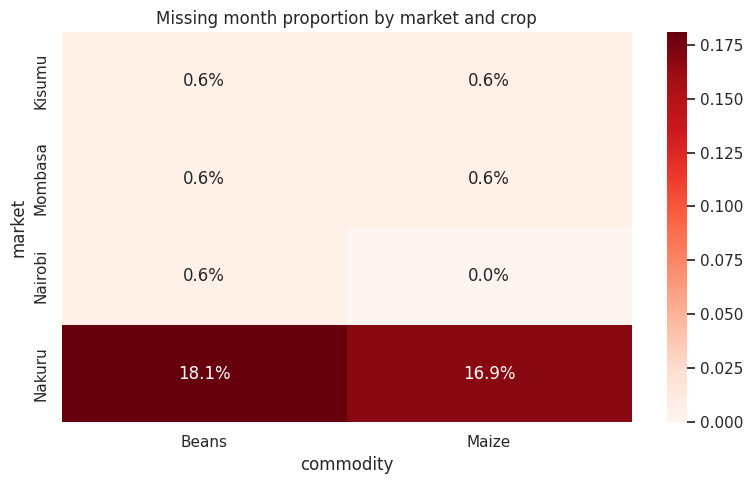

In [9]:
plt.figure(figsize=(8, 5))
sns.heatmap(missingness_summary.pivot(index='market', columns='commodity', values='missing_proportion'), annot=True, fmt='.1%', cmap='Reds')
plt.title('Missing month proportion by market and crop')
plt.tight_layout()
plt.show()

### 8. Aggregate to monthly frequency

In [10]:
monthly_df = aggregate_to_monthly(df)
monthly_df.tail()

,market,commodity,month,avg_price_per_kg
2031,Nakuru,Sorghum,2019-06-01,55.555556
2032,Nakuru,Sorghum,2019-07-01,62.666667
2033,Nakuru,Sorghum,2019-08-01,57.222222
2034,Nakuru,Sorghum,2019-09-01,44.444444
2035,Nakuru,Sorghum,2019-10-01,43.333333


### 9. Reindex against the full calendar to expose gaps explicitly

In [11]:
full_panel = calendar.merge(monthly_df, on=['market', 'commodity', 'month'], how='left')
print(f'Total expected rows: {len(calendar)}')
print(f'Rows with an observed price: {full_panel["avg_price_per_kg"].notna().sum()}')

Total expected rows: 1328
Rows with an observed price: 1265


### 10. Diagnose missing-month gap lengths

In [12]:
gap_runs = diagnose_missing_gap_lengths(full_panel, value_col='avg_price_per_kg')
print(gap_runs['gap_length_months'].describe())
gap_runs.groupby('gap_length_months').size().sort_index()

count    15.000000
mean      4.200000
std       8.247943
min       1.000000
25%       1.000000
50%       1.000000
75%       1.000000
max      25.000000
Name: gap_length_months, dtype: float64


,0
gap_length_months,
1,12
2,1
24,1
25,1


### 11. WFP-only gap handling: short forward-fill, medium seasonal fill, long gaps explicit

Short gaps (up to two months) are forward-filled from prior WFP prices. Medium gaps (three to six months) use same-calendar-month values from prior years only. These WFP-derived fills remain in the panel with provenance labels. FEWS gap fills and extensions are intentionally excluded from this experiment. Longer unresolved gaps remain missing rather than being bridged or treated as observed.

In [13]:
full_panel = forward_fill_short_gaps(full_panel, value_col='avg_price_per_kg', max_gap_months=2)
full_panel = seasonal_interpolate_medium_gaps(full_panel, value_col='avg_price_per_kg', min_gap_months=3, max_gap_months=6)

full_panel['impute_method'] = 'observed'
full_panel.loc[full_panel['was_imputed'], 'impute_method'] = 'short_gap_ffill'
full_panel.loc[full_panel['was_interpolated'], 'impute_method'] = 'medium_gap_seasonal'
full_panel.loc[full_panel['avg_price_per_kg'].isna(), 'impute_method'] = 'long_gap_unfilled'

print(full_panel['impute_method'].value_counts())
print(f'Remaining missing after tiered fill: {full_panel["avg_price_per_kg"].isna().sum()}')

impute_method
observed             1265
long_gap_unfilled      49
short_gap_ffill        14
Name: count, dtype: int64
Remaining missing after tiered fill: 49


### 12. Verify gap handling: what was filled and what remains

In [14]:
fill_counts = full_panel['impute_method'].value_counts().rename('rows')
fill_share = (fill_counts / len(full_panel)).rename('share')
print(pd.concat([fill_counts, fill_share.map('{:.2%}'.format)], axis=1), '\n')

print(f'Calendar months expected : {len(calendar)}')
print(f'Panel rows present       : {len(full_panel)}')
print(f'Absent calendar rows     : {len(calendar) - len(full_panel)}')
print(f'Null prices remaining    : {int(full_panel["avg_price_per_kg"].isna().sum())}\n')

# quantify_missingness treats a row as observed only if it carries a price.
post_fill_missingness = quantify_missingness(
    full_panel[full_panel['avg_price_per_kg'].notna()], calendar
)

fill_audit = missingness_summary.merge(
    post_fill_missingness, on=['market', 'commodity'], suffixes=('_before', '_after')
)
fill_audit['months_recovered'] = (
    fill_audit['missing_months_before'] - fill_audit['missing_months_after']
)
fill_audit[[
    'market', 'commodity', 'missing_months_before', 'months_recovered',
    'missing_months_after', 'missing_proportion_after',
]]

                   rows   share
impute_method                  
observed           1265  95.26%
long_gap_unfilled    49   3.69%
short_gap_ffill      14   1.05% 

Calendar months expected : 1328
Panel rows present       : 1328
Absent calendar rows     : 0
Null prices remaining    : 49

Overall missingness: 3.69%


,market,commodity,missing_months_before,months_recovered,missing_months_after,missing_proportion_after
0,Kisumu,Beans,1,1,0,0.000000
1,Kisumu,Maize,1,1,0,0.000000
2,Mombasa,Beans,1,1,0,0.000000
3,Mombasa,Maize,1,1,0,0.000000
4,Nairobi,Beans,1,1,0,0.000000
5,Nairobi,Maize,0,0,0,0.000000
6,Nakuru,Beans,30,6,24,0.144578
7,Nakuru,Maize,28,3,25,0.150602


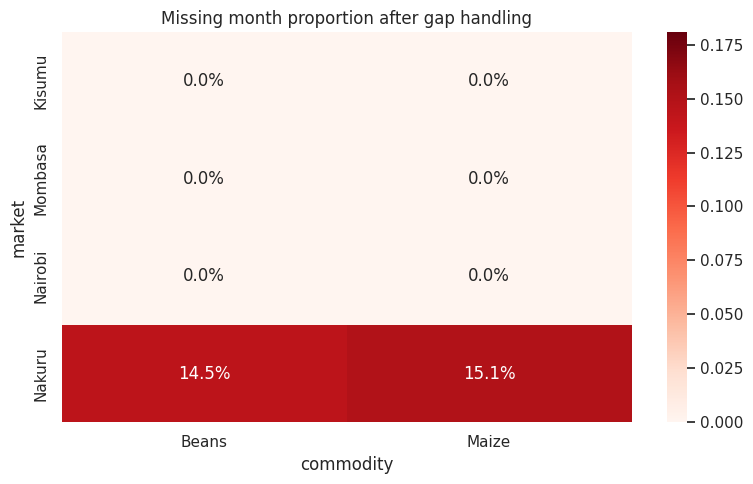

In [15]:
plt.figure(figsize=(8, 5))
sns.heatmap(
    post_fill_missingness.pivot(index='market', columns='commodity', values='missing_proportion'),
    annot=True,
    fmt='.1%',
    cmap='Reds',
    vmin=0,
    vmax=missingness_summary['missing_proportion'].max(),  # shared scale with the pre-fill heatmap
)
plt.title('Missing month proportion after gap handling')
plt.tight_layout()
plt.show()

In [16]:
absent_rows = len(calendar) - len(full_panel)
unfilled = full_panel[full_panel['avg_price_per_kg'].isna()]

print(f'Every market-crop-month present in panel: {absent_rows == 0}')
print(f'Months still without a price           : {len(unfilled)}')

if len(unfilled):
    print('\nRemaining gaps are the >6-month runs left unfilled by design:')
    display(
        unfilled.groupby(['market', 'commodity'])['month']
        .agg(first_missing='min', last_missing='max', months='count')
    )
else:
    print('\nNo missing months or prices remain.')

Every market-crop-month present in panel: True
Months still without a price           : 49

Remaining gaps are the >6-month runs left unfilled by design:


first_missing last_missing  months
market commodity                                   
Nakuru Beans        2006-01-01   2007-12-01      24
       Maize        2006-01-01   2008-01-01      25

In [17]:
missing_rows = list_missing_rows(full_panel, value_col='avg_price_per_kg')

# Leading/trailing runs are coverage limits to truncate; interior runs are true reporting gaps.
print(missing_rows['gap_position'].value_counts(), '\n')
print(
    missing_rows.groupby(['market', 'commodity', 'gap_position'])['month']
    .agg(first_missing='min', last_missing='max', months='count')
)

missing_rows[['market', 'commodity', 'month', 'gap_position', 'gap_length_months', 'month_in_gap']]

gap_position
leading    49
Name: count, dtype: int64 

                              first_missing last_missing  months
market commodity gap_position                                   
Nakuru Beans     leading         2006-01-01   2007-12-01      24
       Maize     leading         2006-01-01   2008-01-01      25


,market,commodity,month,gap_position,gap_length_months,month_in_gap
0,Nakuru,Beans,2006-01-01,leading,24,1
1,Nakuru,Beans,2006-02-01,leading,24,2
2,Nakuru,Beans,2006-03-01,leading,24,3
3,Nakuru,Beans,2006-04-01,leading,24,4
4,Nakuru,Beans,2006-05-01,leading,24,5
5,Nakuru,Beans,2006-06-01,leading,24,6
6,Nakuru,Beans,2006-07-01,leading,24,7
7,Nakuru,Beans,2006-08-01,leading,24,8
8,Nakuru,Beans,2006-09-01,leading,24,9
9,Nakuru,Beans,2006-10-01,leading,24,10


In [18]:
missing_rows_since_2014 = missing_rows[missing_rows['month'] >= '2014-01-01']

print(f'Missing rows from 2014 onward: {len(missing_rows_since_2014)}')
print(missing_rows_since_2014['gap_position'].value_counts())

missing_rows_since_2014[['market', 'commodity', 'month', 'gap_position', 'gap_length_months', 'month_in_gap']]

Missing rows from 2014 onward: 0
Series([], Name: count, dtype: int64)


,market,commodity,month,gap_position,gap_length_months,month_in_gap


### 13. Flag outliers 

In [19]:
observed_prices = full_panel['avg_price_per_kg'].where(full_panel['impute_method'].eq('observed'))
groupers = [full_panel['market'], full_panel['commodity']]
q1 = observed_prices.groupby(groupers).transform(lambda values: values.quantile(0.25))
q3 = observed_prices.groupby(groupers).transform(lambda values: values.quantile(0.75))
iqr = q3 - q1
full_panel['is_outlier'] = full_panel['avg_price_per_kg'].notna() & (
    (full_panel['avg_price_per_kg'] < q1 - 1.5 * iqr)
    | (full_panel['avg_price_per_kg'] > q3 + 1.5 * iqr)
)
print(f'Diagnostic outlier flags (not a training feature): {full_panel["is_outlier"].sum()}')
full_panel[full_panel['is_outlier']]

Diagnostic outlier flags (not a training feature): 16


,market,commodity,month,avg_price_per_kg,was_imputed,was_interpolated,impute_method,is_outlier
302,Kisumu,Maize,2017-05-01,58.583889,False,False,observed,True
303,Kisumu,Maize,2017-06-01,57.121111,False,False,observed,True
444,Mombasa,Beans,2015-05-01,94.400000,False,False,observed,True
466,Mombasa,Beans,2017-03-01,92.681667,False,False,observed,True
467,Mombasa,Beans,2017-04-01,98.080556,False,False,observed,True
468,Mombasa,Beans,2017-05-01,98.445000,False,False,observed,True
634,Mombasa,Maize,2017-05-01,55.056111,False,False,observed,True
828,Nairobi,Beans,2019-09-01,96.555556,False,False,observed,True
829,Nairobi,Beans,2019-10-01,113.244444,False,False,observed,True
967,Nairobi,Maize,2017-06-01,54.755556,False,False,observed,True


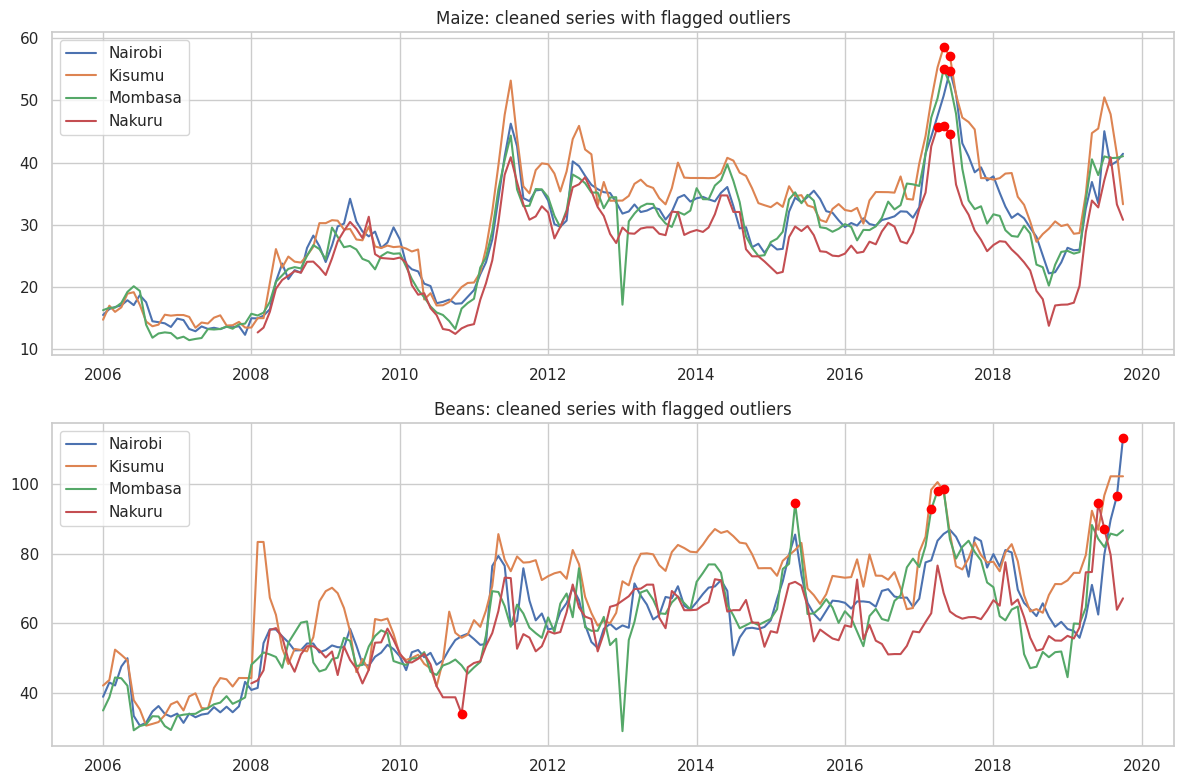

In [20]:
fig, axes = plt.subplots(len(CROPS), 1, figsize=(12, 4 * len(CROPS)))
for ax, crop in zip(axes, CROPS):
    subset = full_panel[full_panel['commodity'] == crop]
    for market in MARKETS:
        market_subset = subset[subset['market'] == market]
        ax.plot(market_subset['month'], market_subset['avg_price_per_kg'], label=market)
        outliers = market_subset[market_subset['is_outlier']]
        ax.scatter(outliers['month'], outliers['avg_price_per_kg'], color='red', zorder=5)
    ax.set_title(f'{crop}: cleaned series with flagged outliers')
    ax.legend()
plt.tight_layout()
plt.show()

### 14. Apply observed-WFP coverage windows

Coverage metadata is calculated from original observed WFP rows only, not from filled prices. The canonical panel retains WFP-derived imputed rows within each series' observed coverage. It includes pre-2010 WFP history as feature warm-up; supervised target rows will later be restricted to January 2010 through October 2019.

In [21]:
observed_panel = full_panel[full_panel['impute_method'].eq('observed')].copy()
coverage_check = (
    observed_panel.groupby(['market', 'commodity'])['month']
    .agg(
        first_observed_month='min',
        last_observed_month='max',
        observed_months='count',
    )
    .reset_index()
)
coverage_check

,market,commodity,first_observed_month,last_observed_month,observed_months
0,Kisumu,Beans,2006-01-01,2019-10-01,165
1,Kisumu,Maize,2006-01-01,2019-10-01,165
2,Mombasa,Beans,2006-01-01,2019-10-01,165
3,Mombasa,Maize,2006-01-01,2019-10-01,165
4,Nairobi,Beans,2006-01-01,2019-10-01,165
5,Nairobi,Maize,2006-01-01,2019-10-01,166
6,Nakuru,Beans,2008-01-01,2019-10-01,136
7,Nakuru,Maize,2008-02-01,2019-10-01,138


In [22]:
final_df = full_panel.merge(
    coverage_check,
    on=['market', 'commodity'],
    how='inner',
)
final_df = final_df[
    (final_df['month'] >= final_df['first_observed_month'])
    & (final_df['month'] <= final_df['last_observed_month'])
].copy()

final_missing = final_df[final_df['avg_price_per_kg'].isna()]
print(f'Per-series panel rows: {len(final_df)}')
print(f'Rows with a price: {final_df["avg_price_per_kg"].notna().sum()}')
print(f'Internal missing target rows: {len(final_missing)}')
print(f'Series retained: {coverage_check.shape[0]}')

final_df.groupby(['market', 'commodity']).agg(
    window_start=('month', 'min'),
    window_end=('month', 'max'),
    rows=('month', 'size'),
    missing_targets=('avg_price_per_kg', lambda values: values.isna().sum()),
)

Per-series panel rows: 1279
Rows with a price: 1279
Internal missing target rows: 0
Series retained: 8


window_start window_end  rows  missing_targets
market  commodity                                               
Kisumu  Beans       2006-01-01 2019-10-01   166                0
        Maize       2006-01-01 2019-10-01   166                0
Mombasa Beans       2006-01-01 2019-10-01   166                0
        Maize       2006-01-01 2019-10-01   166                0
Nairobi Beans       2006-01-01 2019-10-01   166                0
        Maize       2006-01-01 2019-10-01   166                0
Nakuru  Beans       2008-01-01 2019-10-01   142                0
        Maize       2008-02-01 2019-10-01   141                0

In [23]:
missing_target_rows = final_df[final_df['avg_price_per_kg'].isna()].copy()

print(f'Missing target rows: {len(missing_target_rows)}')
print('\nMissing targets by market and commodity:')
print(missing_target_rows.groupby(['market', 'commodity']).size().rename('missing_rows'))

print('\nMissing target dates by series:')
missing_target_summary = (
    missing_target_rows.groupby(['market', 'commodity'])['month']
    .agg(first_missing='min', last_missing='max', missing_months='count')
    .reset_index()
)
display(missing_target_summary)

print('\nExact missing-target rows:')
missing_target_rows[
    [
        'market',
        'commodity',
        'month',
        'avg_price_per_kg',
        'impute_method',
        'is_outlier',
    ]
]

Missing target rows: 0

Missing targets by market and commodity:
Series([], Name: missing_rows, dtype: int64)

Missing target dates by series:


,market,commodity,first_missing,last_missing,missing_months



Exact missing-target rows:


,market,commodity,month,avg_price_per_kg,impute_method,is_outlier


In [24]:
final_df.head()

,market,commodity,month,avg_price_per_kg,was_imputed,was_interpolated,impute_method,is_outlier,first_observed_month,last_observed_month,observed_months
0,Kisumu,Beans,2006-01-01,42.027222,False,False,observed,False,2006-01-01,2019-10-01,165
1,Kisumu,Beans,2006-02-01,43.617222,False,False,observed,False,2006-01-01,2019-10-01,165
2,Kisumu,Beans,2006-03-01,52.343333,False,False,observed,False,2006-01-01,2019-10-01,165
3,Kisumu,Beans,2006-04-01,50.852778,False,False,observed,False,2006-01-01,2019-10-01,165
4,Kisumu,Beans,2006-05-01,49.283889,False,False,observed,False,2006-01-01,2019-10-01,165


In [25]:
coverage_summary = (
    full_panel[full_panel['avg_price_per_kg'].notna()]
    .groupby(['market', 'commodity'])
    .agg(
        first_record=('month', 'min'),
        last_record=('month', 'max'),
        total_months=('month', 'count'),
    )
    .reset_index()
)

impute_breakdown = (
    full_panel[full_panel['avg_price_per_kg'].notna()]
    .groupby(['market', 'commodity', 'impute_method'])
    .size()
    .unstack(fill_value=0)
    .reset_index()
)

coverage_summary = coverage_summary.merge(impute_breakdown, on=['market', 'commodity'], how='left')
coverage_summary = coverage_summary.sort_values(['market', 'commodity']).reset_index(drop=True)
print(coverage_summary.to_string(index=False))
coverage_summary

 market commodity first_record last_record  total_months  observed  short_gap_ffill
 Kisumu     Beans   2006-01-01  2019-10-01           166       165                1
 Kisumu     Maize   2006-01-01  2019-10-01           166       165                1
Mombasa     Beans   2006-01-01  2019-10-01           166       165                1
Mombasa     Maize   2006-01-01  2019-10-01           166       165                1
Nairobi     Beans   2006-01-01  2019-10-01           166       165                1
Nairobi     Maize   2006-01-01  2019-10-01           166       166                0
 Nakuru     Beans   2008-01-01  2019-10-01           142       136                6
 Nakuru     Maize   2008-02-01  2019-10-01           141       138                3


,market,commodity,first_record,last_record,total_months,observed,short_gap_ffill
0,Kisumu,Beans,2006-01-01,2019-10-01,166,165,1
1,Kisumu,Maize,2006-01-01,2019-10-01,166,165,1
2,Mombasa,Beans,2006-01-01,2019-10-01,166,165,1
3,Mombasa,Maize,2006-01-01,2019-10-01,166,165,1
4,Nairobi,Beans,2006-01-01,2019-10-01,166,165,1
5,Nairobi,Maize,2006-01-01,2019-10-01,166,166,0
6,Nakuru,Beans,2008-01-01,2019-10-01,142,136,6
7,Nakuru,Maize,2008-02-01,2019-10-01,141,138,3


### 15. Save cleaned dataset

In [27]:
if not IN_COLAB:
    raise RuntimeError('Run this notebook in Colab with Google Drive mounted to save the CSV to Drive.')

OUTPUT_PATH = Path('/content/drive/MyDrive/capstone-data/cleaned_monthly_prices_wfp_2010_2019-10.csv')
OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)
final_df.to_csv(OUTPUT_PATH, index=False)

print(f'Canonical WFP panel saved to Google Drive: {OUTPUT_PATH}: {len(final_df)} rows')
print(
    f'Model target window {MODEL_TARGET_START:%Y-%m} to {WFP_CUTOFF:%Y-%m}: '
    f'{len(model_window)} rows'
)
print(model_window['impute_method'].value_counts())

Canonical WFP panel saved to Google Drive: /content/drive/MyDrive/capstone-data/cleaned_monthly_prices_wfp_2010_2019-10.csv: 1279 rows
Model target window 2010-01 to 2019-10: 944 rows
impute_method
observed           932
short_gap_ffill     12
Name: count, dtype: int64
